# A2. Segmentación de mercado

**Materia:** INF432 — Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales — RetailMarket Santa Cruz  
**Autora:** Yossy Carmelita Yanma Villarroel  
**Registro:** 217182844

## 1. Entendimiento del negocio

### Contexto
RetailMarket Santa Cruz es una empresa minorista hipotética que necesita
conocer las diferencias entre sus clientes para diseñar promociones
y estrategias comerciales adaptadas a sus hábitos de compra.

### Pregunta de negocio
¿Qué grupos de clientes existen y qué estrategia comercial diferenciada
merece cada uno?

### Objetivo del análisis
Identificar grupos de clientes con características y comportamientos
de compra similares, describir sus perfiles y proponer acciones
comerciales para cada segmento.

### Decisión que apoya
Definir promociones, combinaciones de productos y canales de contacto
adecuados para cada segmento.

### Responsables de la decisión
Gerente de Marketing y Jefe de Categorías.

## 2. Metodología del análisis

Se utilizará la base preparada en `00_Datos.ipynb`, disponible en
`data/processed/data_limpia_original.csv`.

El análisis comprende:
1. Selección y revisión de las variables de segmentación.
2. Estandarización mediante StandardScaler.
3. Aplicación de PCA y análisis de la varianza explicada.
4. Evaluación del número de grupos para k-means mediante silueta
   y utilidad comercial.
5. Comparación con clustering jerárquico y su dendrograma.
6. Descripción de los segmentos en unidades originales.
7. Asignación de nombres comerciales y recomendaciones.

La variable `Response` no se utilizará para formar los grupos,
porque este análisis es no supervisado.

## 3. Configuración y carga de datos

Importamos las librerías para trabajar con los datos, generar gráficos,
estandarizar las variables, aplicar PCA y comparar k-means con
clustering jerárquico.

Fijamos la semilla en 1 para reproducir los resultados.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Semilla acordada por el equipo
SEMILLA = 1
np.random.seed(SEMILLA)

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


### 3.1 Carga y verificación de la base limpia

Cargamos los datos preparados por Diogo, conservando sus valores
en unidades originales. Verificamos la cantidad de registros,
las columnas disponibles y los valores faltantes antes de
seleccionar las variables de segmentación.

In [2]:
# Ruta relativa desde la carpeta del proyecto
ruta_datos = Path("data/processed/data_limpia_original.csv")

# Verificar que exista el archivo
if not ruta_datos.is_file():
    raise FileNotFoundError(
        f"No se encontró: {ruta_datos}. "
        "Comprueba que abriste la carpeta del repositorio."
    )

# Cargar la base sin modificar el archivo original
df = pd.read_csv(ruta_datos)

print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()}")

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeros cinco registros:")
display(df.head())

Cantidad de registros: 2236
Cantidad de columnas: 29
Valores faltantes: 0

Columnas disponibles:
['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age', 'Total_Spent', 'Total_Purchases', 'Children', 'Family_Size', 'Customer_Days', 'Education_Level']

Primeros cinco registros:


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,AcceptedCmp2,Complain,Response,Age,Total_Spent,Total_Purchases,Children,Family_Size,Customer_Days,Education_Level
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,1,69,1617,22,0,1,663,2
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,72,27,4,2,3,113,2
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,0,0,61,776,20,0,2,312,2
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,0,0,42,53,6,1,3,139,2
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,45,422,14,1,3,161,4


### 3.2 Selección de variables para la segmentación

Seleccionamos variables que describen los ingresos y el comportamiento
de compra: recencia, gasto por categoría, compras por canal,
compras con descuento y visitas al sitio web.

No incluimos Response ni las respuestas a campañas anteriores,
porque buscamos segmentos basados en el perfil comercial y de compra.

Total_Spent y Total_Purchases se conservan para interpretar los
segmentos, pero no se incluyen como entradas junto con las variables
que los componen, para evitar dar peso adicional a la misma información.

Las variables demográficas y de antigüedad quedan disponibles
para describir los grupos después del agrupamiento.

In [3]:
# Variables utilizadas para formar los grupos
variables_segmentacion = [
    "Income",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

# Copia de las variables en sus unidades originales
X_original = df[variables_segmentacion].copy()

print(f"Clientes para segmentar: {X_original.shape[0]}")
print(f"Variables seleccionadas: {X_original.shape[1]}")
print(f"Todas son numéricas: {all(pd.api.types.is_numeric_dtype(X_original[c]) for c in X_original.columns)}")
print(f"Valores faltantes: {X_original.isna().sum().sum()}")

print("\nEstadísticas de las variables seleccionadas:")
display(X_original.describe().T.round(2))

Clientes para segmentar: 2236
Variables seleccionadas: 13
Todas son numéricas: True
Valores faltantes: 0

Estadísticas de las variables seleccionadas:


,count,mean,std,min,25%,50%,75%,max
Income,2236.0,51952.61,21411.47,1730.0,35502.5,51381.5,68275.75,162397.0
Recency,2236.0,49.12,28.96,0.0,24.0,49.0,74.00,99.0
MntWines,2236.0,304.13,336.59,0.0,24.0,174.0,504.25,1493.0
MntFruits,2236.0,26.28,39.72,0.0,1.0,8.0,33.00,199.0
MntMeatProducts,2236.0,166.98,225.69,0.0,16.0,67.0,232.00,1725.0
MntFishProducts,2236.0,37.54,54.65,0.0,3.0,12.0,50.00,259.0
MntSweetProducts,2236.0,27.08,41.30,0.0,1.0,8.0,33.00,263.0
MntGoldProds,2236.0,43.98,52.06,0.0,9.0,24.0,56.00,362.0
NumDealsPurchases,2236.0,2.33,1.93,0.0,1.0,2.0,3.00,15.0
NumWebPurchases,2236.0,4.09,2.78,0.0,2.0,4.0,6.00,27.0


### 3.3 Distribución de las variables seleccionadas

Utilizamos histogramas para observar los valores más frecuentes,
la dispersión y la presencia de distribuciones asimétricas.

Esta revisión permite comprender las diferencias entre clientes
antes de estandarizar las variables y aplicar los modelos.
Los valores elevados no se eliminan automáticamente, ya que
pueden representar comportamientos comerciales reales.

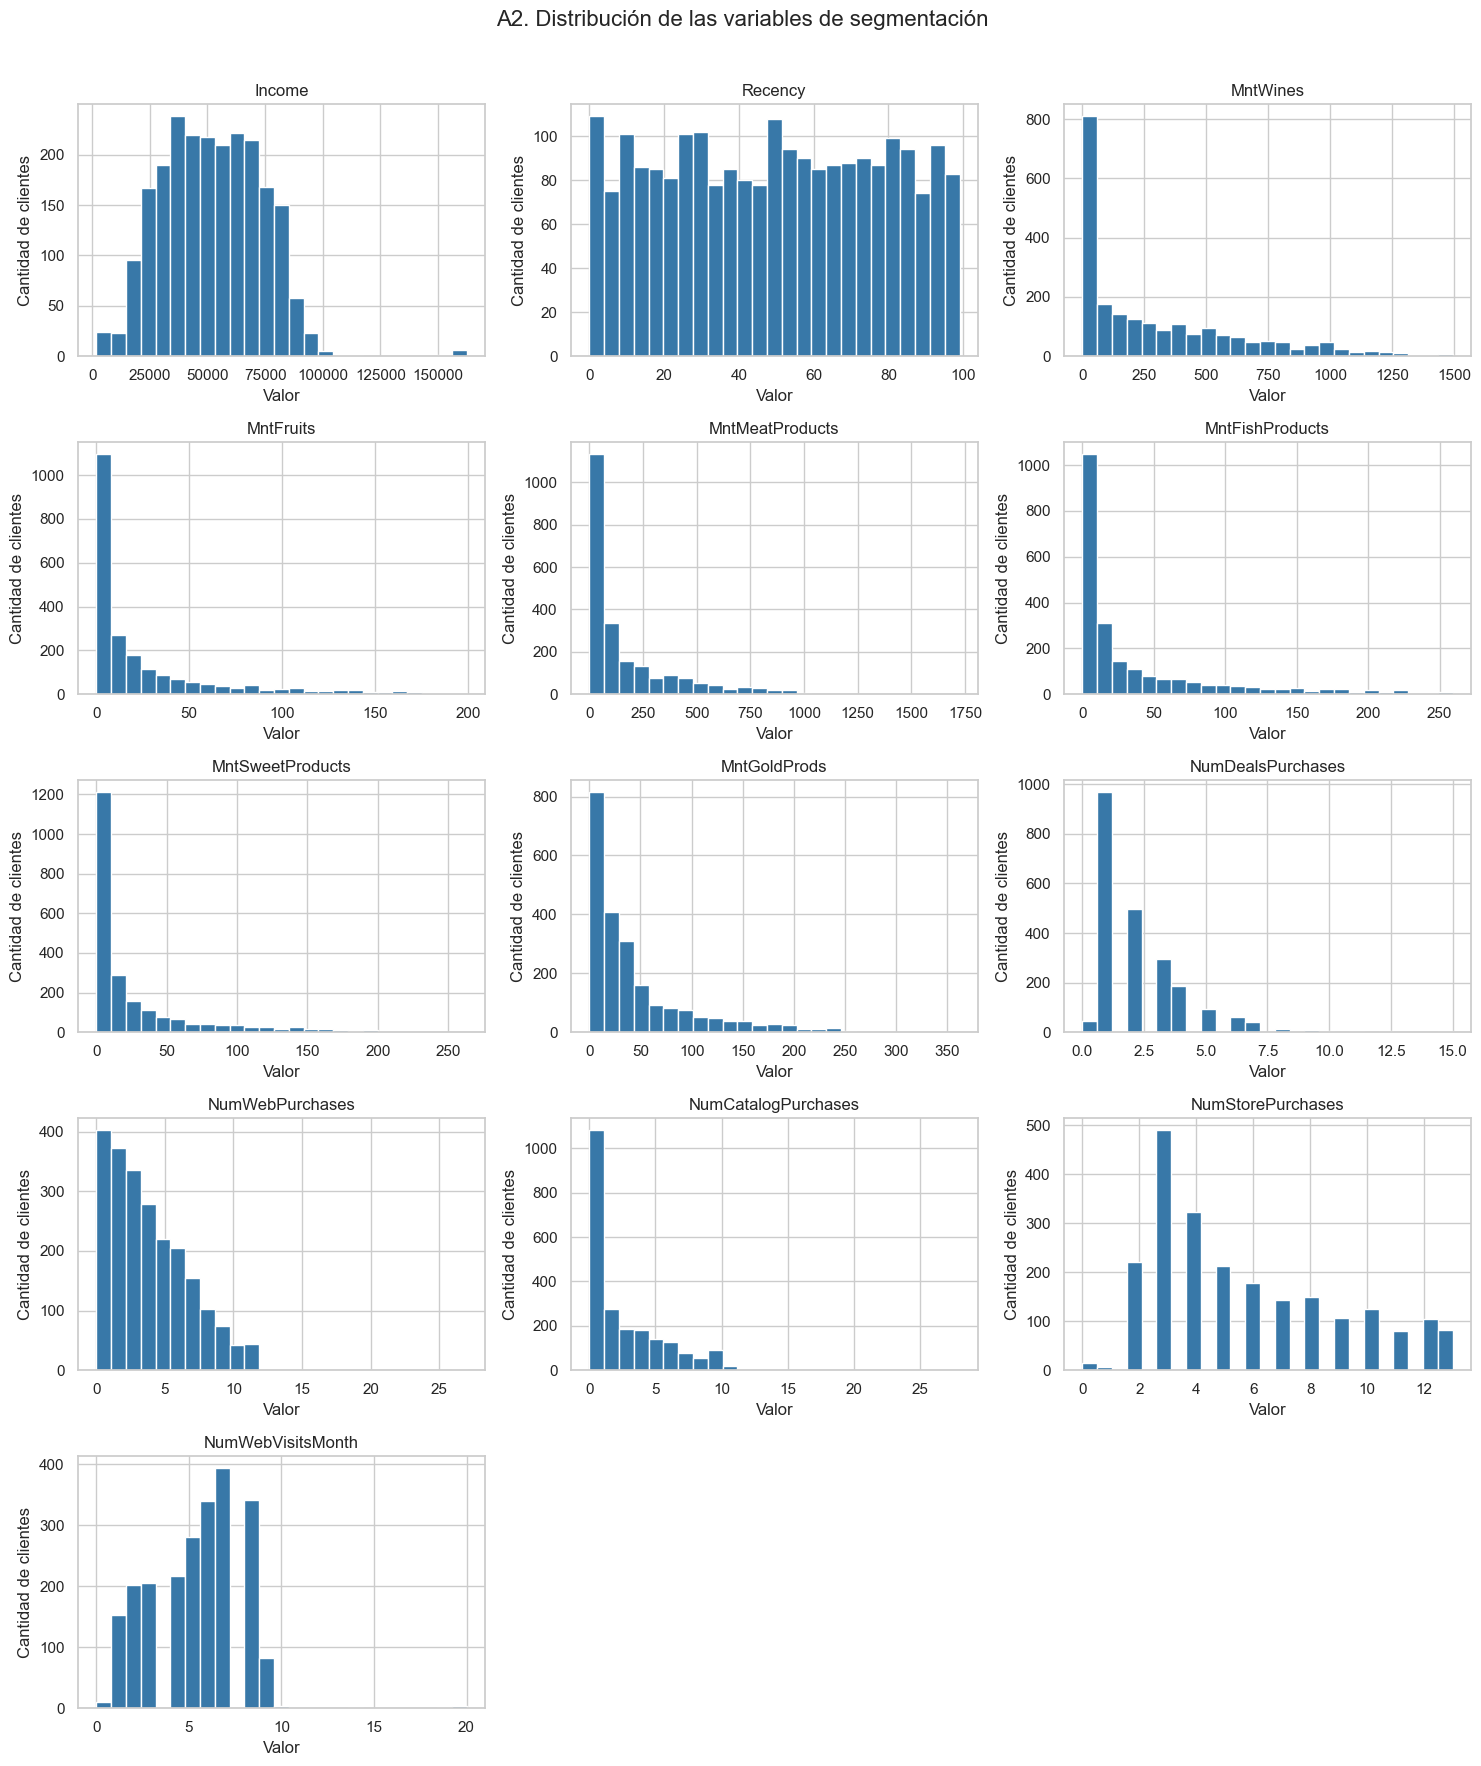

In [4]:
# Carpeta para guardar los gráficos de nuestra área
ruta_figuras = Path("reports/figures")
ruta_figuras.mkdir(parents=True, exist_ok=True)

# Histogramas: cada variable conserva su propia escala
fig, axes = plt.subplots(5, 3, figsize=(15, 18))
axes = axes.ravel()

for ax, columna in zip(axes, variables_segmentacion):
    ax.hist(
        X_original[columna],
        bins=25,
        color="#3878A8",
        edgecolor="white"
    )
    ax.set_title(columna)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Cantidad de clientes")

# Ocultar los espacios que no se utilizan
for ax in axes[len(variables_segmentacion):]:
    ax.set_visible(False)

fig.suptitle(
    "A2. Distribución de las variables de segmentación",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    ruta_figuras / "A2_01_histogramas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación de las distribuciones

Los gastos por categoría presentan asimetría hacia la derecha:
muchos clientes registran gastos bajos y una cantidad menor
presenta gastos elevados.

Las compras por web y catálogo también se concentran en cantidades
bajas. Las compras en tienda muestran una distribución más extendida.
La recencia presenta una distribución aproximadamente uniforme
entre 0 y 99 días.

Estas diferencias permiten explorar segmentos según intensidad
de compra, categorías y canales utilizados. Los histogramas por sí
solos no demuestran la existencia de grupos separados.

### 3.4 Estandarización de las variables

Aplicamos StandardScaler para que cada variable tenga media
aproximadamente cero y desviación estándar uno. Así evitamos que
las diferencias de unidades, como ingresos frente a cantidad de
compras, dominen el cálculo de distancias.

La estandarización no elimina los valores extremos ni corrige
la asimetría; esta sensibilidad se considerará como una limitación.

Utilizamos los 2.236 clientes para explorar la segmentación de
la base actual. La división 70/30 corresponde al análisis
supervisado de campañas.

Conservamos X_original para interpretar los segmentos en sus
unidades originales.

In [5]:
# Ajustar el escalador y transformar las 13 variables seleccionadas
scaler_segmentacion = StandardScaler()

X_scaled = pd.DataFrame(
    scaler_segmentacion.fit_transform(X_original),
    columns=X_original.columns,
    index=X_original.index
)

# Comprobar el resultado de la estandarización
verificacion_escalado = pd.DataFrame({
    "Media": X_scaled.mean(),
    "Desviación estándar": X_scaled.std(ddof=0)
})

print("Dimensiones de la base estandarizada:", X_scaled.shape)
display(verificacion_escalado.round(6))

Dimensiones de la base estandarizada: (2236, 13)


,Media,Desviación estándar
Income,-0.0,1.0
Recency,-0.0,1.0
MntWines,-0.0,1.0
MntFruits,-0.0,1.0
MntMeatProducts,-0.0,1.0
MntFishProducts,0.0,1.0
MntSweetProducts,0.0,1.0
MntGoldProds,0.0,1.0
NumDealsPurchases,0.0,1.0
NumWebPurchases,0.0,1.0


## 4. Reducción de dimensionalidad con PCA

PCA combina las 13 variables estandarizadas en componentes
principales que resumen su variabilidad.

Primero calculamos todos los componentes y examinamos su varianza
explicada individual y acumulada. Elegiremos el menor número de
componentes que conserve al menos el 85 % de la varianza total,
como compromiso entre reducción y conservación de información.

Este porcentaje no representa exactitud de predicción.
Posteriormente utilizaremos los dos primeros componentes
para visualizar los clientes en un gráfico.

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.63,44.63
1,PC2,11.90,56.53
2,PC3,7.71,64.24
3,PC4,6.95,71.20
4,PC5,5.21,76.40
5,PC6,4.83,81.23
6,PC7,4.04,85.27
7,PC8,3.49,88.76
8,PC9,3.07,91.83
9,PC10,2.78,94.60


Componentes seleccionados: 7
Varianza conservada: 85.27%


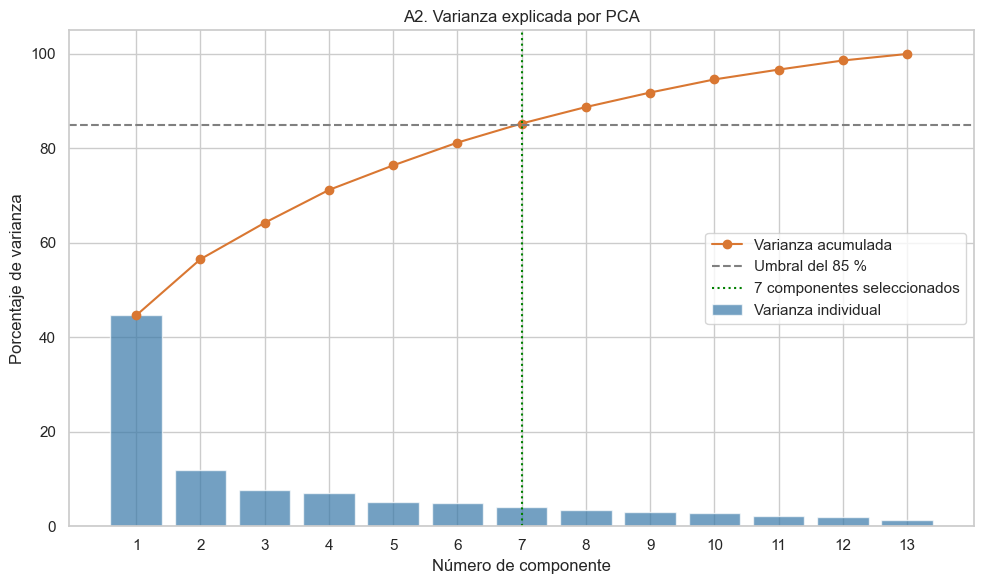

In [6]:
# Calcular todos los componentes principales
pca_completo = PCA(svd_solver="full")
pca_completo.fit(X_scaled)

varianza_individual = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

# Menor cantidad de componentes que alcanza el 85 %
UMBRAL_VARIANZA = 0.85
n_componentes = int(
    np.searchsorted(varianza_acumulada, UMBRAL_VARIANZA) + 1
)

tabla_varianza = pd.DataFrame({
    "Componente": [
        f"PC{i + 1}" for i in range(len(varianza_individual))
    ],
    "Varianza explicada (%)": varianza_individual * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

display(tabla_varianza.round(2))

print(f"Componentes seleccionados: {n_componentes}")
print(
    "Varianza conservada: "
    f"{varianza_acumulada[n_componentes - 1]:.2%}"
)

# Gráfico de varianza individual y acumulada
componentes = np.arange(1, len(varianza_individual) + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    componentes,
    varianza_individual * 100,
    color="#3878A8",
    alpha=0.7,
    label="Varianza individual"
)

ax.plot(
    componentes,
    varianza_acumulada * 100,
    marker="o",
    color="#D97732",
    label="Varianza acumulada"
)

ax.axhline(
    UMBRAL_VARIANZA * 100,
    color="gray",
    linestyle="--",
    label="Umbral del 85 %"
)

ax.axvline(
    n_componentes,
    color="green",
    linestyle=":",
    label=f"{n_componentes} componentes seleccionados"
)

ax.set(
    title="A2. Varianza explicada por PCA",
    xlabel="Número de componente",
    ylabel="Porcentaje de varianza",
    xticks=componentes,
    ylim=(0, 105)
)

ax.legend()
plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_02_varianza_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()